Story so far: Healthy largely passes, aside from small cluster of stromal cells and some endothelial cells. Disease has large set of epithelial "failing" cells/nhoods, including what query annotated as "AS-epithelium" and normal "epithelium". Also a subset of stromal cells, that was not annotated as anything special in query. Note that another putative AS-specific subset ("AS-uAS-uSMC") *does* mix with reference, with "whole uterus" samples (see "Group" in reference), and this cell state is not disease-specific. Check paper if they do claim that. Currently, we don't see these as "passed" cells/nhoods, as there are too few reference datasets mapping with that query subset. Consider changing filters.
To do: look into AS-epithelium, AS-uAS-uSMC, and other stromal descriptions in paper. AS epithelium: high in SLPI1, HSPA1A, SOCS3 according to paper. 


Further mapQC to-do: for cell-level results, calculate these based on cell's sample's (z)scores in different neighborhoods, rather than on entire neighborhood score! I think this makes more sense. Try it out on Monday. 


Also look into pan cancer Laughney mapping... (try mapping with different max_kl_weight?)


And see if max_kl_weight scVI thing can be fixed...

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import random
import sys

sys.path.append("../../mapqc/")
import mapqc
import plotting

In [2]:
%load_ext autoreload
%autoreload 2
%load_ext lab_black

In [3]:
sc.set_figure_params(figsize=(5, 5))

In [4]:
query_batch = "Santamaria_2023"

In [5]:
adata = sc.read_h5ad(
    "../../data/HECA/queries_mapped/Asherman_syndrome_mapped_emb_subsetted_and_processed.h5ad"
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


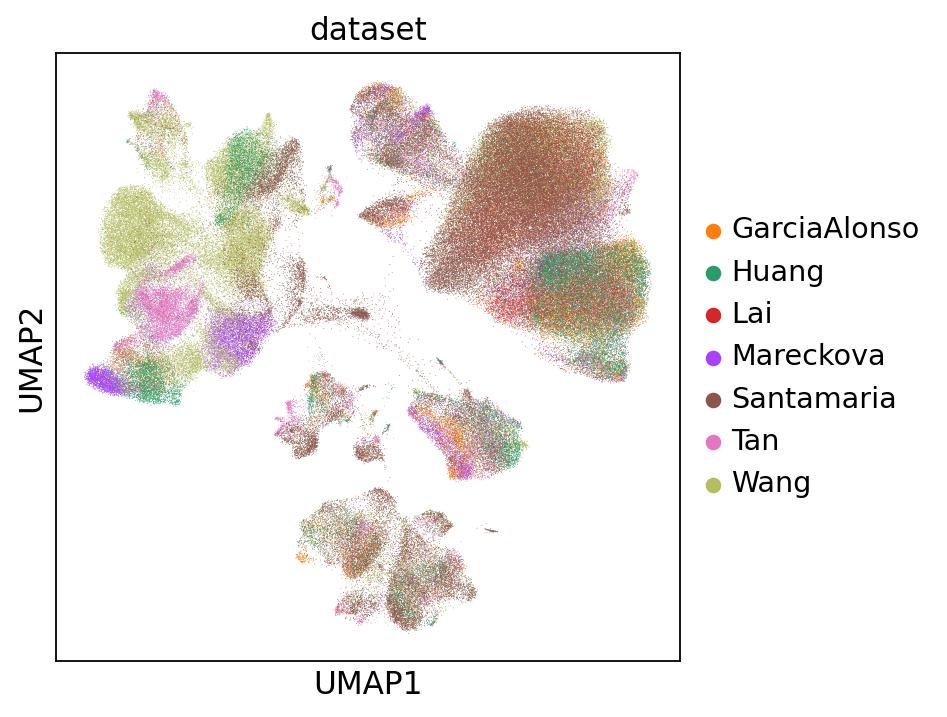

In [6]:
sc.pl.umap(adata, color="dataset")

!! collagenase + trypsin!! preprocessing also in query (but only for epithelial cells?)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_utils.py:430: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


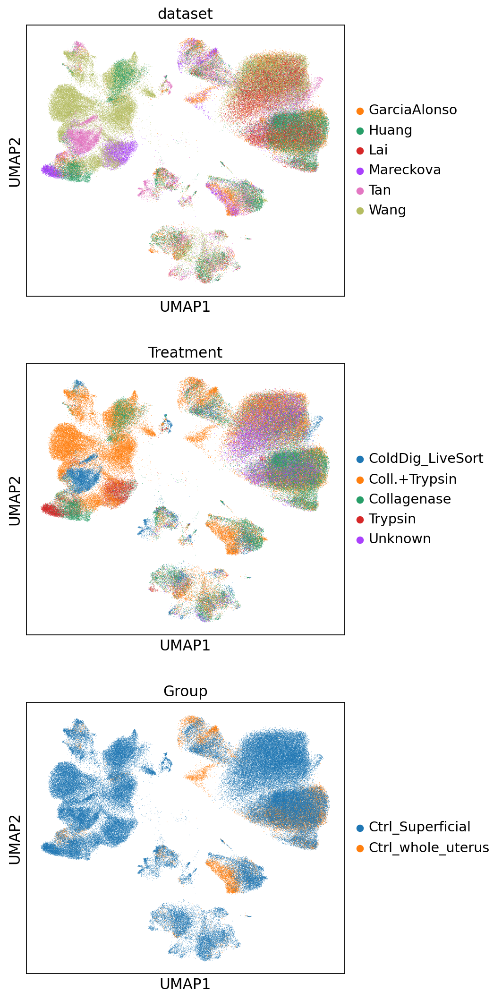

In [7]:
sc.pl.umap(
    adata[adata.obs.ref_or_query == "ref", :],
    color=["dataset", "Treatment", "Group"],
    ncols=1,
)

In [8]:
adata.obs.groupby("dataset").agg({"Treatment": "unique"})

,Treatment
dataset,
GarciaAlonso,"['Coll.+Trypsin', 'Collagenase', 'Trypsin'] Ca..."
Huang,"['Collagenase'] Categories (5, object): ['Cold..."
Lai,"['Unknown'] Categories (5, object): ['ColdDig_..."
Mareckova,"['Coll.+Trypsin', 'Collagenase', 'Trypsin'] Ca..."
Santamaria,"[NaN] Categories (5, object): ['ColdDig_LiveSo..."
Tan,"['ColdDig_LiveSort'] Categories (5, object): [..."
Wang,"['Coll.+Trypsin'] Categories (5, object): ['Co..."


In [9]:
adata

AnnData object with n_obs × n_vars = 227735 × 10
    obs: 'n_genes', 'sample', 'library', 'Processing', 'Treatment', '10x kit', 'percent_mito', 'n_counts', 'scrublet_score', 'genotype', 'Library_genotype', 'Group', 'Endometriosis_stage', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Biopsy_type', 'Tissue_sampled', 'Age', 'Endometrial_pathology', 'celltype', 'lineage', 'label_long', '_scvi_batch', '_scvi_labels', 'nCount_RNA', 'nFeature_RNA', 'mitochondria_ratio', 'menstrual_cycle_day', 'principal_cell_types', 'batch', 'ref_or_query', 'leiden'
    uns: 'dataset_colors', 'neighbors', 'umap'
    obsm: 'X_umap'
    obsp: 'connectivities', 'distances'

In [10]:
ref_q_key = "ref_or_query"
ref_cat = "ref"
query_cat = "query"
batch_key = "dataset"  # try out 'sample' as well...
sample_key = "sample"
condition_key = "Group"
coi_healthy = "WOI Control"
coi_disease = "AS"
emb_key = "X"

## Healthy:

In [11]:
print(f"Subsetting query to condition {coi_healthy}")
adata_healthy = adata[
    (adata.obs[ref_q_key] == ref_cat) | (adata.obs[condition_key] == coi_healthy)
].copy()

Subsetting query to condition WOI Control


In [12]:
print(
    "number of query samples left:",
    len(
        adata_healthy.obs.loc[
            adata_healthy.obs[ref_q_key] == query_cat, "sample"
        ].unique()
    ),
)

number of query samples left: 6


In [13]:
adata.shape

(227735, 10)

In [14]:
adata_healthy.shape

(187399, 10)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


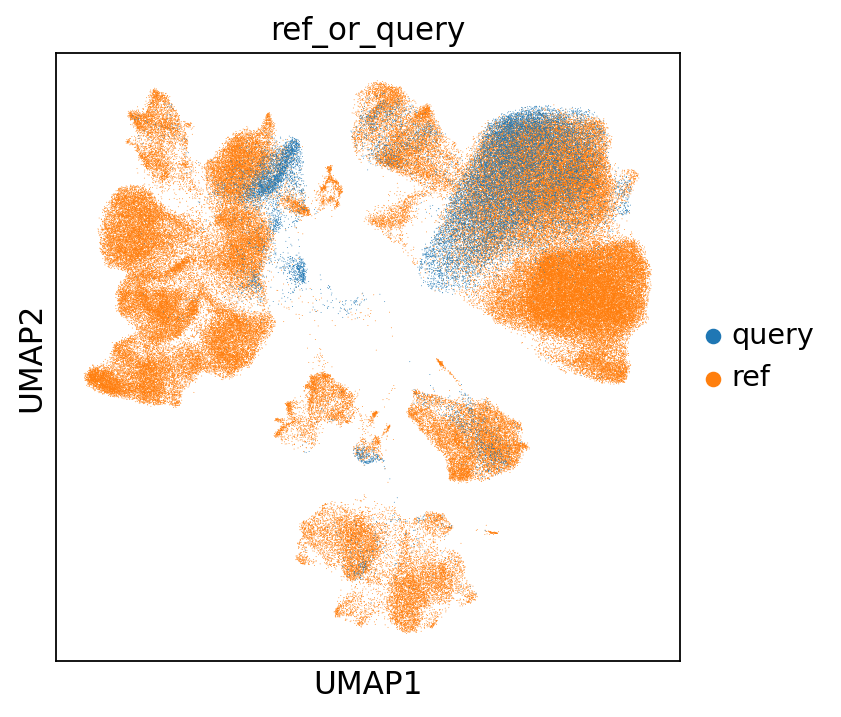

In [15]:
sc.pl.umap(adata_healthy, color=ref_q_key)

#### run MapQC:

In [16]:
k = int((adata.obs[ref_q_key] == ref_cat).sum() / 200)
max_k = int(k * 2)
n_nhoods_healthy = int((adata_healthy.obs[ref_q_key] == query_cat).sum() / k * 10)

In [17]:
print(f"n nhoods healthy: {n_nhoods_healthy}, k: {k}, max k: {max_k}")

n nhoods healthy: 225, k: 842, max k: 1684


In [18]:
query_cell_idc_healthy = np.where(adata_healthy.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_healthy = random.sample(query_cell_idc_healthy, k=n_nhoods_healthy)
center_cells_healthy = np.array(
    adata_healthy.obs.iloc[center_cell_idc_healthy, :].index
)

In [19]:
results_healthy = mapqc.mapQC_results(
    adata=adata_healthy,
    center_cells=center_cells_healthy,
    k=k,
    emb_key=emb_key,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key=batch_key,
    exclude_same_batch_for_ref_samples=False,  # exceptional! normally set to True,
    use_adaptive_k=True,
    max_k=max_k,
    min_n_samples_q=1,
)

In [20]:
results_healthy.calculate_sample_dists_to_ref_samples()

225it [00:28,  7.78it/s]
../../mapqc/mapqc.py:199: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
../../mapqc/mapqc.py:224: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


100% of neighborhoods passed filtering. (For more details, see [mapqc_object]._nhood_filtered)


In [21]:
results_healthy._nhood_filtered.value_counts()

pass                     224
too few query samples      1
dtype: int64

In [22]:
results_healthy.calculate_nhood_statistics(q=66)

2% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.
For 20% of filtered neighborhoods, >34% of samples are more than two standard deviations above the mean distance from the reference.
17% of query samples (1 sample(s)) consistently do not mix well with the reference.
If these are control samples, consider removing them from the query and re-mapping.
For more information, check .sample_median_dist_to_ref_across_nhoods
or run plotting.plot_sample_distances_to_reference.


../../mapqc/mapqc.py:364: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,


In [23]:
results_healthy.calculate_cell_statistics_using_sample_level_results_per_nhood()

Percentage of query cells showing low sample-mixing: 20.78.


### Plot

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


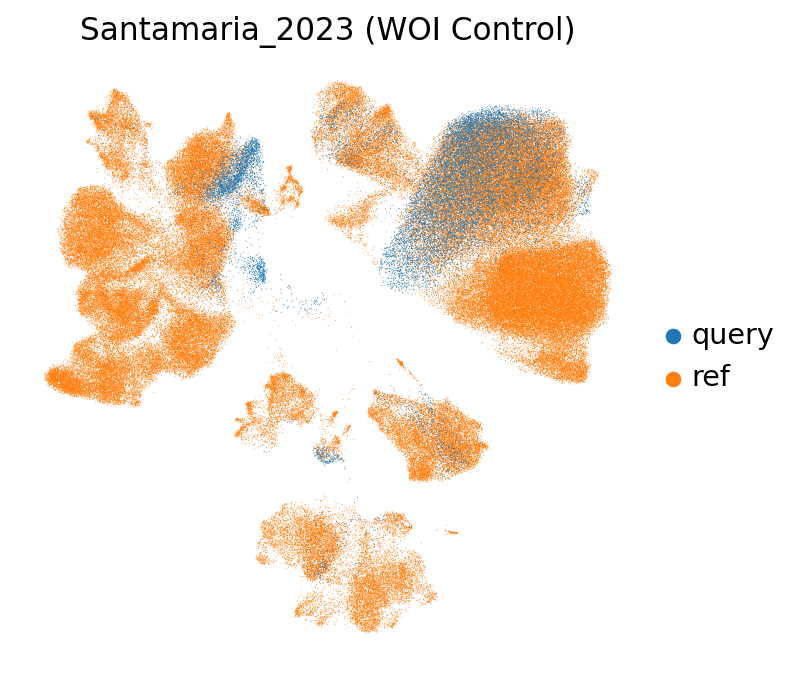

In [24]:
sc.pl.umap(
    results_healthy.adata,
    color=ref_q_key,
    palette={
        results_healthy.ref_cat: "tab:orange",
        results_healthy.query_cat: "tab:blue",
    },
    title=f"{query_batch} ({coi_healthy})",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


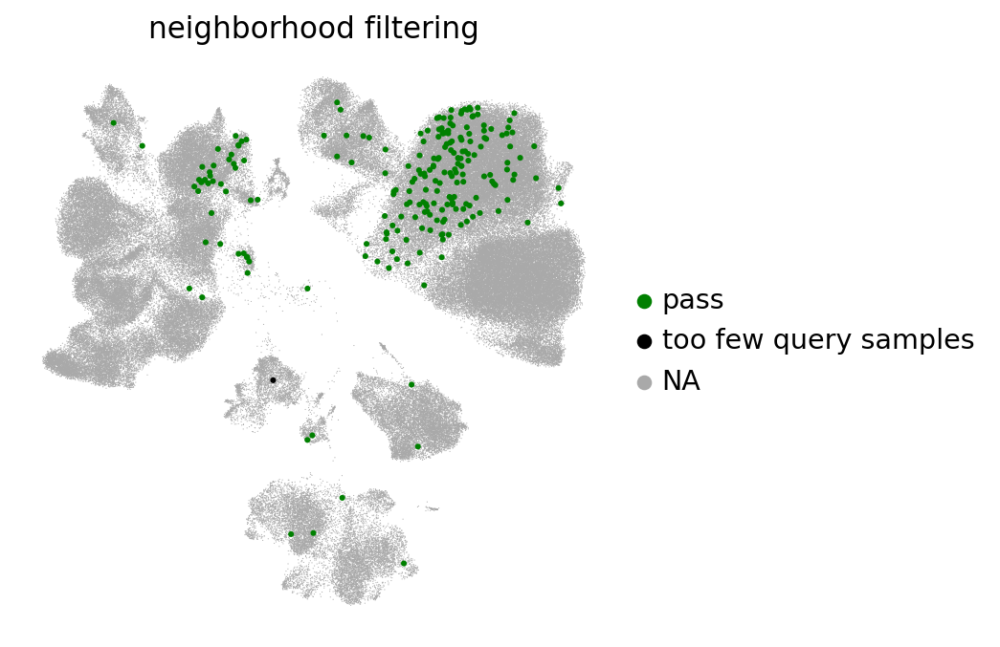

In [25]:
plotting.plot_umap_filtering_info(results_healthy)

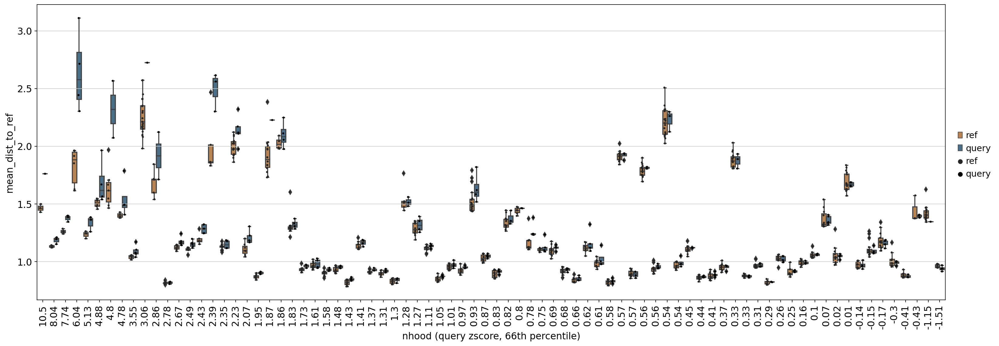

In [26]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_healthy, use_zscored_dists=False
)

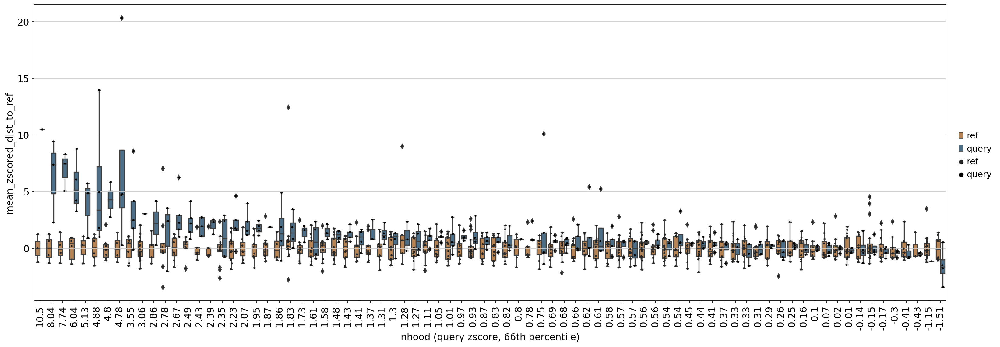

In [27]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_healthy, use_zscored_dists=True
)

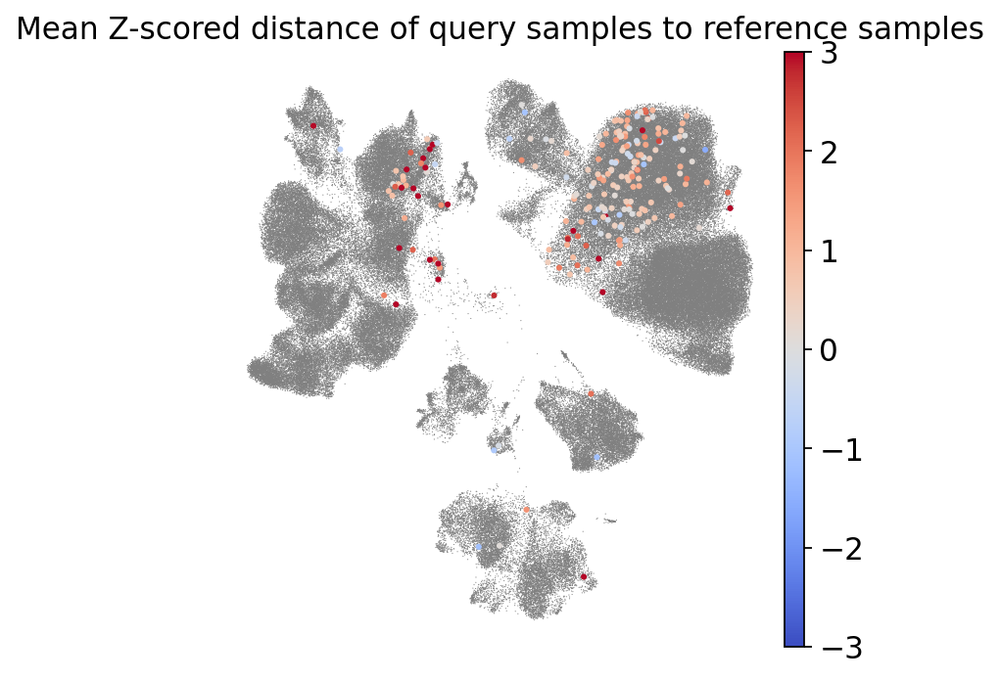

In [28]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy, color_by="mean_zscore")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


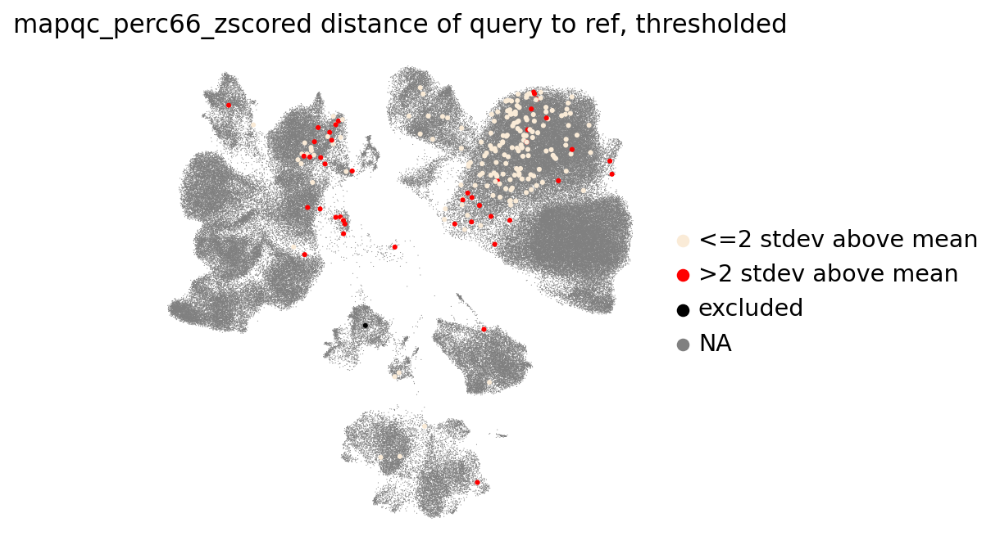

In [29]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy, color_by="percq_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


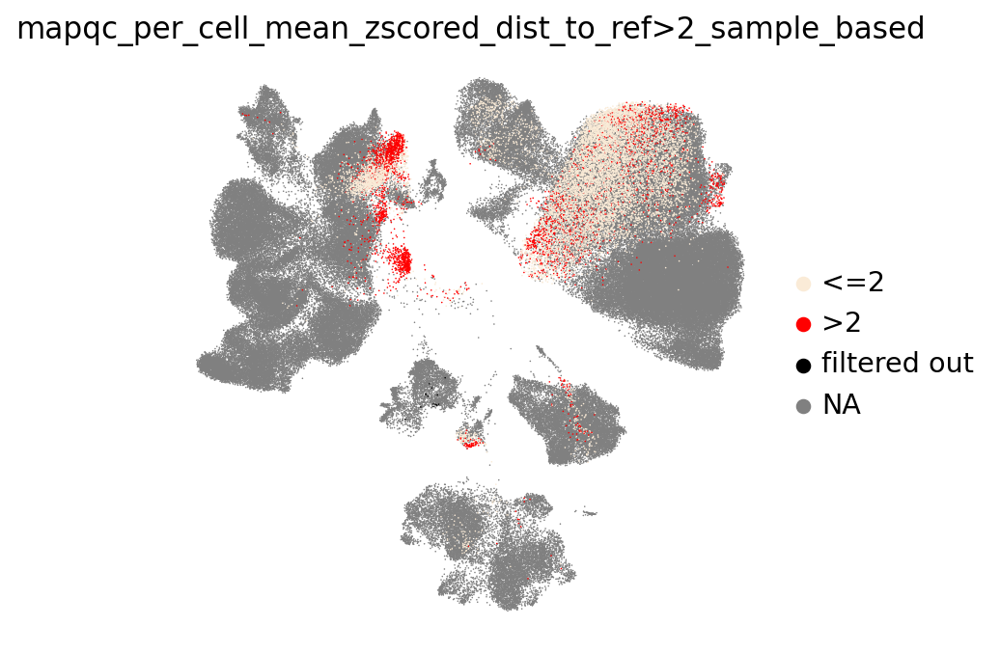

In [30]:
plotting.plot_umap_cell_level_results(results_healthy, size=2, sample_based=True)

In [31]:
adata.shape

(227735, 10)

In [32]:
results_healthy.adata

AnnData object with n_obs × n_vars = 187399 × 10
    obs: 'n_genes', 'sample', 'library', 'Processing', 'Treatment', '10x kit', 'percent_mito', 'n_counts', 'scrublet_score', 'genotype', 'Library_genotype', 'Group', 'Endometriosis_stage', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Biopsy_type', 'Tissue_sampled', 'Age', 'Endometrial_pathology', 'celltype', 'lineage', 'label_long', '_scvi_batch', '_scvi_labels', 'nCount_RNA', 'nFeature_RNA', 'mitochondria_ratio', 'menstrual_cycle_day', 'principal_cell_types', 'batch', 'ref_or_query', 'leiden', 'mapqc_ref_or_q', 'mapqc_nhood_weight', 'mapqc_pval_corr', 'mapqc_mean_zscored_q_dist_to_ref', 'mapqc_mean_zscore>2', 'mapqc_median_zscore>2', 'mapqc_perc66_zscore>2', 'mapqc_sign', 'mapqc_filter_info', 'mapqc_dotsize', 'mapqc_dotsize_by_nhood_weight', 'mapqc_per_cell_mean_zscored_dist_to_ref_sample_based', 'mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based'
    uns: 'dataset_colors', 'neighbors', 'umap', 'ref_or_query_

In [33]:
pd.crosstab(
    results_healthy.adata.obs["mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based"],
    results_healthy.adata.obs["sample"],
)

sample,run_count_0156_HUT-21A0007_EST-21-G2-EPST65,run_count_0184_HUT-21L0005_EST-29-G2-EPST81,run_count_0184_HUT-21L0007_EST-31-G2-EPST83,run_count_0184_HUT-21L0008_EST-32-G2-EPST84,run_count_0184_HUT-21L0009_EST-33-G2-EPST85,run_count_0192_ASH-21G0011_EST-41-G2-EPST109
mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based,,,,,,
<=2,2621,3019,3527,17,1197,2139
>2,737,812,798,278,103,557
filtered out,3,1,2,4,4,1


../../mapqc/plotting.py:569: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mapqc_results.adata.obs[f"mapqc_nhood_cells_{neighborhood}"].iloc[
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


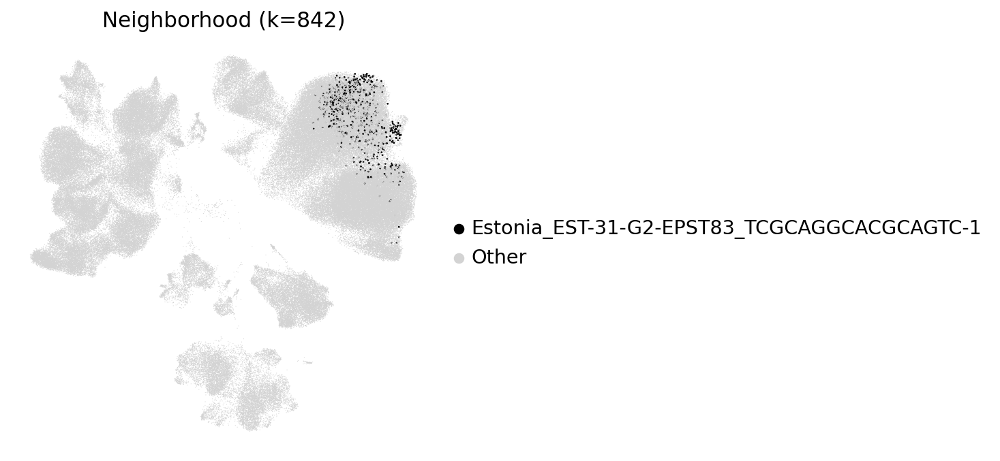

In [34]:
plotting.plot_umap_neighborhood(
    results_healthy, neighborhood="Estonia_EST-31-G2-EPST83_TCGCAGGCACGCAGTC-1"
)

In [35]:
results_healthy.adata.obs["query_sample"] = None
results_healthy.adata.obs.loc[
    results_healthy.adata.obs.ref_or_query == "query", "query_sample"
] = results_healthy.adata.obs.loc[
    results_healthy.adata.obs.ref_or_query == "query", "sample"
]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


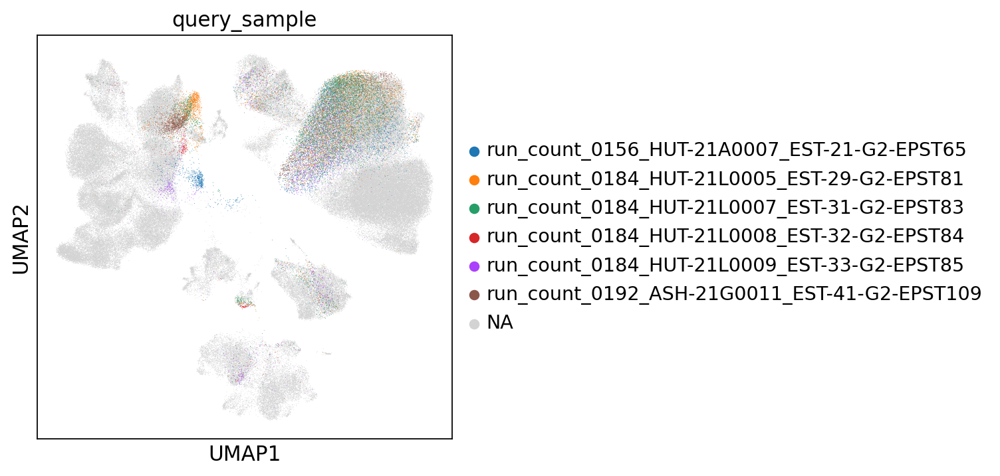

In [36]:
sc.pl.umap(results_healthy.adata, color="query_sample")

In [37]:
adata_query_obs = adata_healthy.obs.loc[adata.obs.ref_or_query == "query", :].copy()

In [38]:
adata_query_obs["sample"] = adata_query_obs["sample"].cat.remove_unused_categories()

In [39]:
adata_query_obs.groupby("sample").agg({"menstrual_cycle_day": "first"})

,menstrual_cycle_day
sample,
run_count_0156_HUT-21A0007_EST-21-G2-EPST65,23
run_count_0184_HUT-21L0005_EST-29-G2-EPST81,23
run_count_0184_HUT-21L0007_EST-31-G2-EPST83,24
run_count_0184_HUT-21L0008_EST-32-G2-EPST84,23
run_count_0184_HUT-21L0009_EST-33-G2-EPST85,21
run_count_0192_ASH-21G0011_EST-41-G2-EPST109,24


In [40]:
adata_query_obs.menstrual_cycle_day.value_counts()

23    8758
24    8434
21    1773
Name: menstrual_cycle_day, dtype: int64

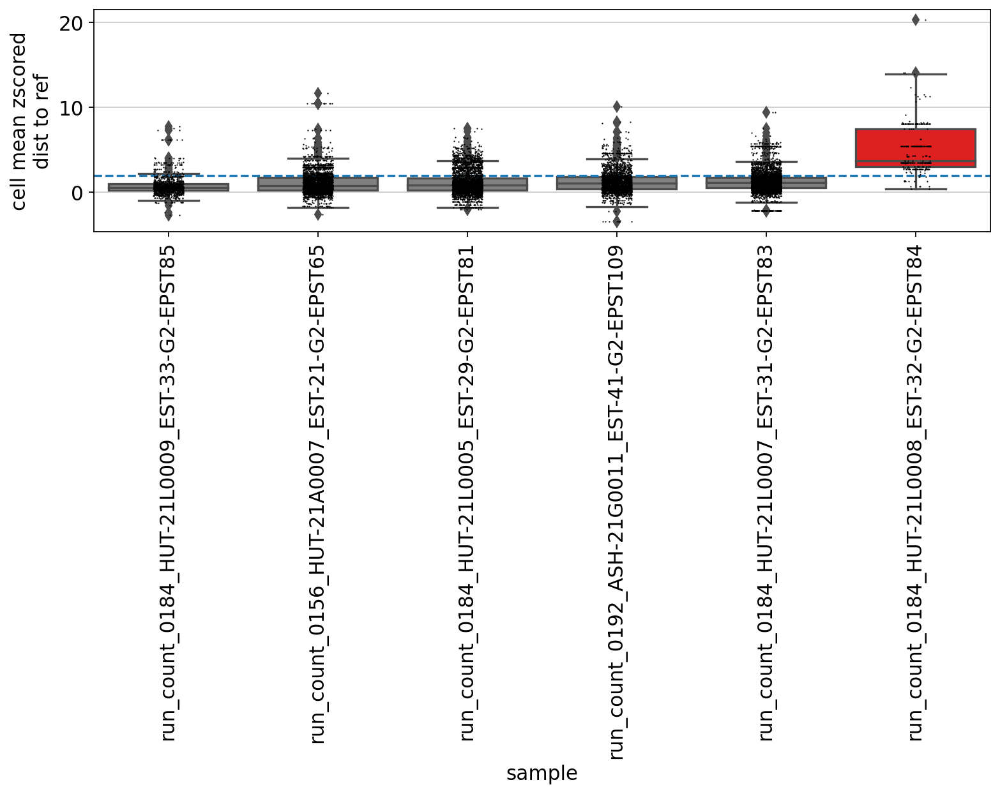

In [41]:
plotting.plot_sample_distances_to_reference_cell_level(results_healthy)

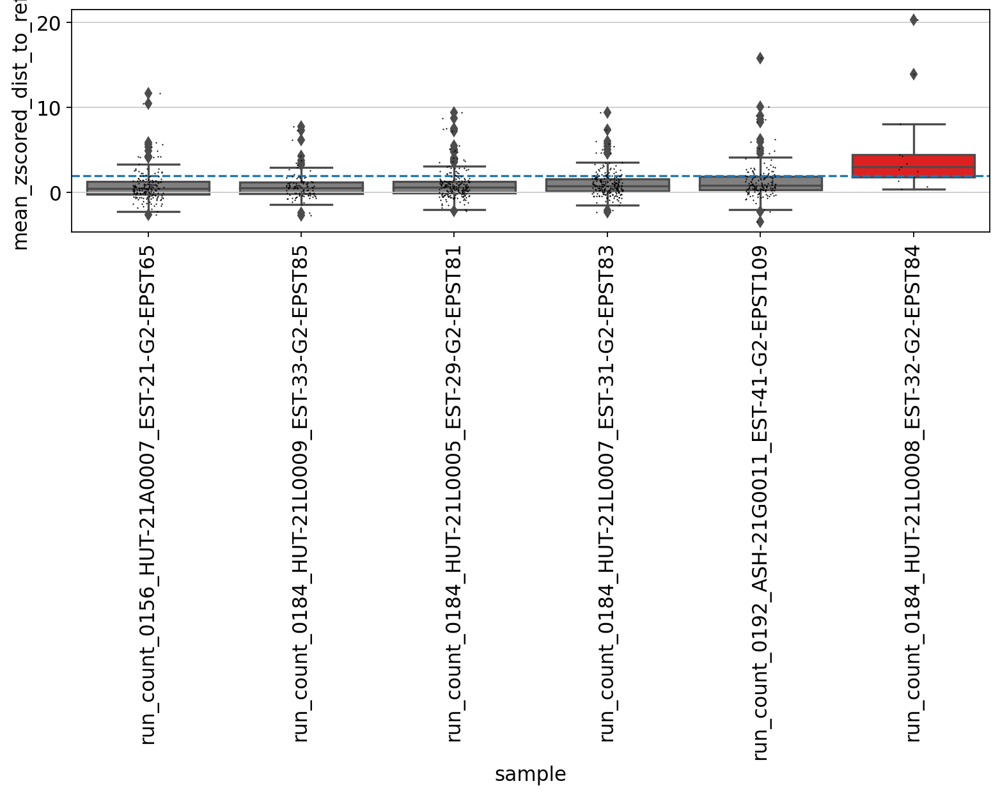

In [42]:
plotting.plot_sample_distances_to_reference(results_healthy)

## Disease:

In [43]:
print(f"Subsetting query to condition {coi_disease}")
adata_disease = adata[
    (adata.obs[ref_q_key] == ref_cat) | (adata.obs[condition_key] == coi_disease)
].copy()

Subsetting query to condition AS


In [44]:
print(
    "number of query samples left:",
    len(
        adata_disease.obs.loc[
            adata_disease.obs[ref_q_key] == query_cat, "sample"
        ].unique()
    ),
)

number of query samples left: 17


In [45]:
n_nhoods_disease = int((adata_disease.obs[ref_q_key] == query_cat).sum() / k * 10)

In [46]:
print(f"n nhoods disease: {n_nhoods_disease}")

n nhoods disease: 479


In [47]:
adata.shape

(227735, 10)

In [48]:
adata_disease.shape

(208770, 10)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


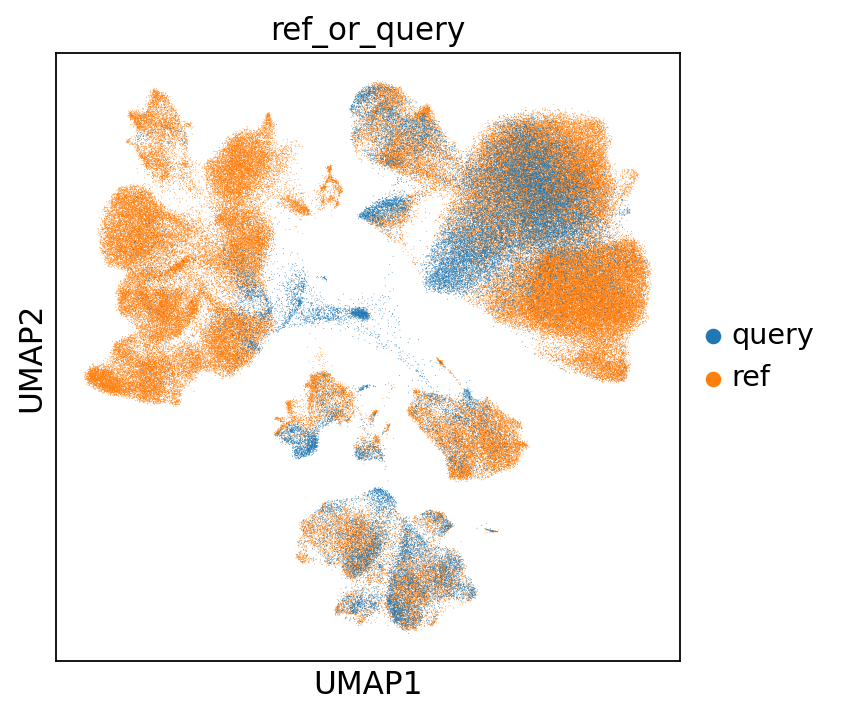

In [49]:
sc.pl.umap(adata_disease, color=ref_q_key)

#### run MapQC:

In [50]:
query_cell_idc_disease = np.where(adata_disease.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_disease = random.sample(query_cell_idc_disease, k=n_nhoods_disease)
center_cells_disease = np.array(
    adata_disease.obs.iloc[center_cell_idc_disease, :].index
)

In [51]:
results_disease = mapqc.mapQC_results(
    adata=adata_disease,
    center_cells=center_cells_disease,
    k=k,
    emb_key=emb_key,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key=batch_key,
    exclude_same_batch_for_ref_samples=False,  # Exceptional! Normally set to True
    use_adaptive_k=True,
    max_k=max_k,
    min_n_samples_q=1,
)

In [52]:
results_disease.calculate_sample_dists_to_ref_samples()

479it [01:22,  5.81it/s]

99% of neighborhoods passed filtering. (For more details, see [mapqc_object]._nhood_filtered)



../../mapqc/mapqc.py:199: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
../../mapqc/mapqc.py:224: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [53]:
results_disease._nhood_filtered.value_counts()

pass                         476
too few query samples          2
too few reference samples      1
dtype: int64

In [54]:
results_disease.calculate_nhood_statistics(q=66)

9% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.
For 27% of filtered neighborhoods, >34% of samples are more than two standard deviations above the mean distance from the reference.
6% of query samples (1 sample(s)) consistently do not mix well with the reference.
If these are control samples, consider removing them from the query and re-mapping.
For more information, check .sample_median_dist_to_ref_across_nhoods
or run plotting.plot_sample_distances_to_reference.


../../mapqc/mapqc.py:364: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,


In [55]:
results_disease.calculate_cell_statistics_using_sample_level_results_per_nhood()

Percentage of query cells showing low sample-mixing: 23.16.


### Plot

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


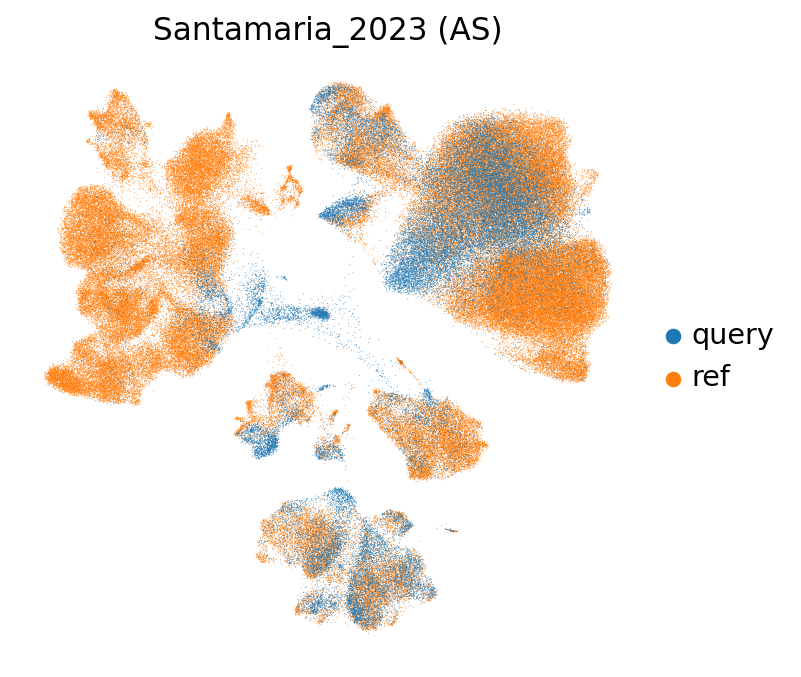

In [56]:
sc.pl.umap(
    results_disease.adata,
    color=ref_q_key,
    palette={
        results_disease.ref_cat: "tab:orange",
        results_disease.query_cat: "tab:blue",
    },
    title=f"{query_batch} ({coi_disease})",
    frameon=False,
)

In [57]:
adata

AnnData object with n_obs × n_vars = 227735 × 10
    obs: 'n_genes', 'sample', 'library', 'Processing', 'Treatment', '10x kit', 'percent_mito', 'n_counts', 'scrublet_score', 'genotype', 'Library_genotype', 'Group', 'Endometriosis_stage', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Biopsy_type', 'Tissue_sampled', 'Age', 'Endometrial_pathology', 'celltype', 'lineage', 'label_long', '_scvi_batch', '_scvi_labels', 'nCount_RNA', 'nFeature_RNA', 'mitochondria_ratio', 'menstrual_cycle_day', 'principal_cell_types', 'batch', 'ref_or_query', 'leiden'
    uns: 'dataset_colors', 'neighbors', 'umap'
    obsm: 'X_umap'
    obsp: 'connectivities', 'distances'

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


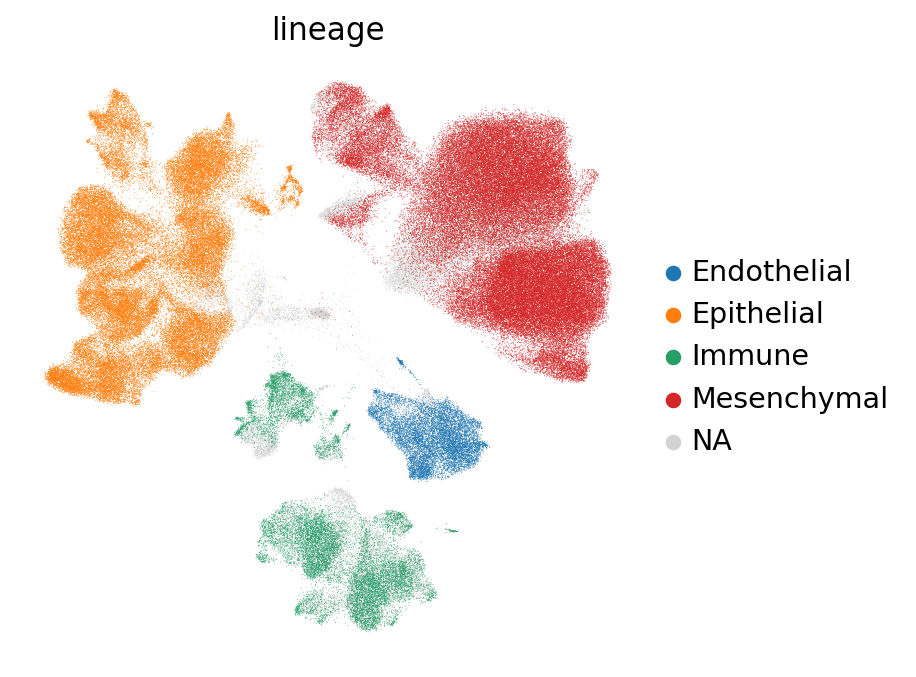

In [58]:
sc.pl.umap(
    results_disease.adata,
    color="lineage",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


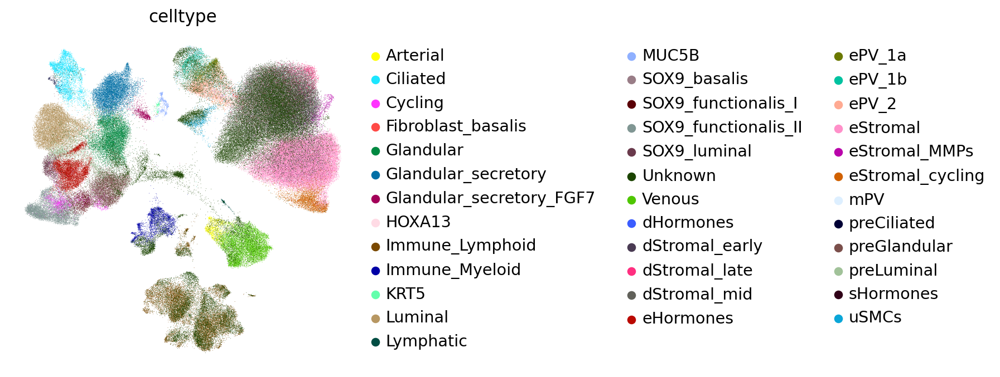

In [59]:
sc.pl.umap(
    results_disease.adata,
    color="celltype",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


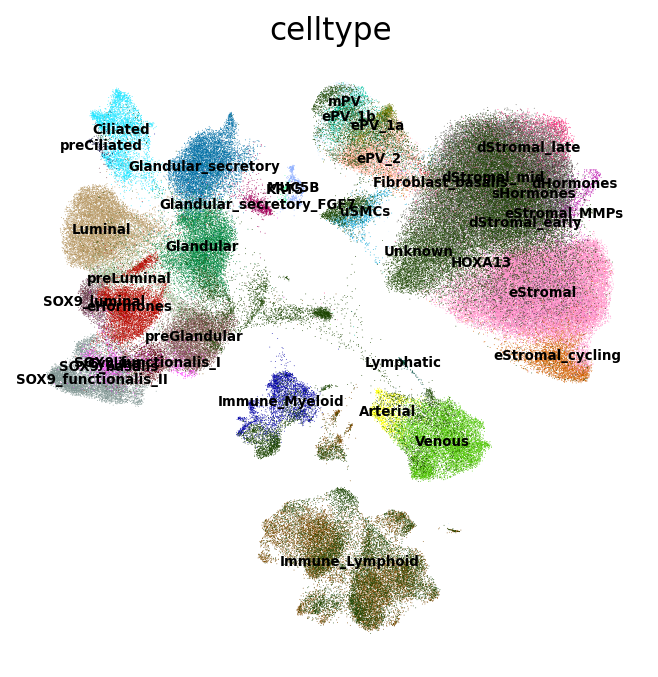

In [60]:
sc.pl.umap(
    results_disease.adata,
    color="celltype",
    frameon=False,
    legend_loc="on data",
    legend_fontsize=6,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


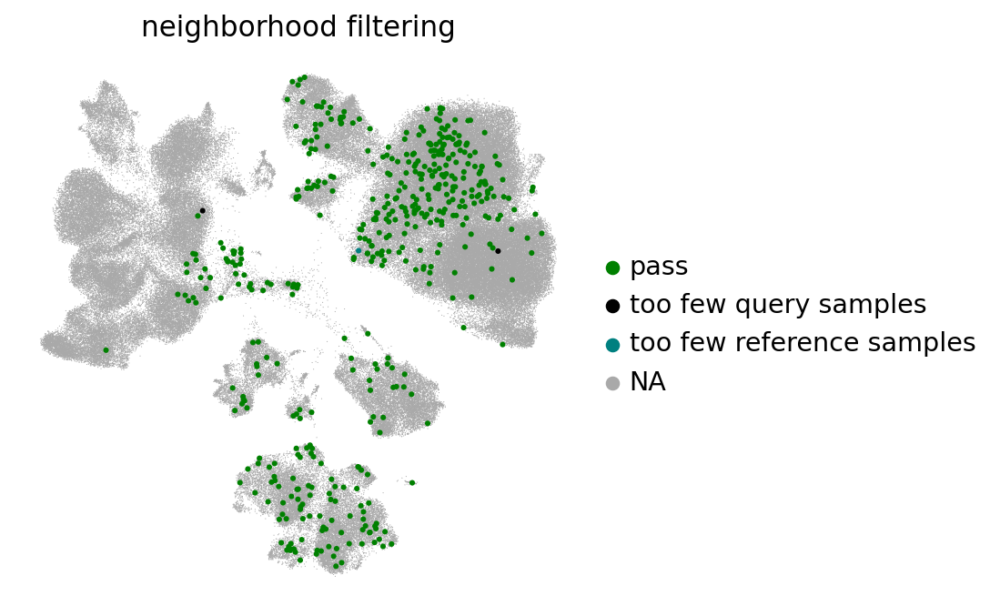

In [61]:
plotting.plot_umap_filtering_info(results_disease)

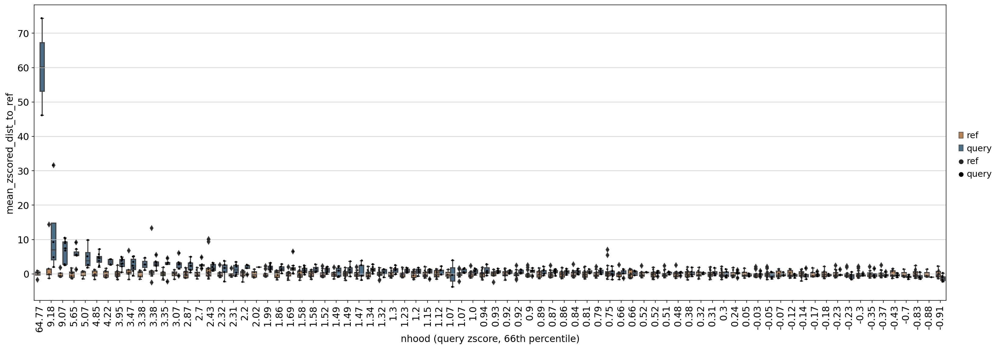

In [62]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_disease, use_zscored_dists=True
)

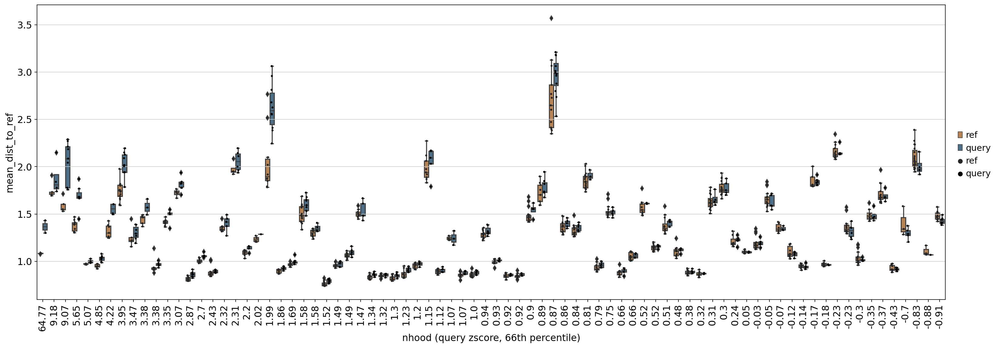

In [63]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_disease, use_zscored_dists=False
)

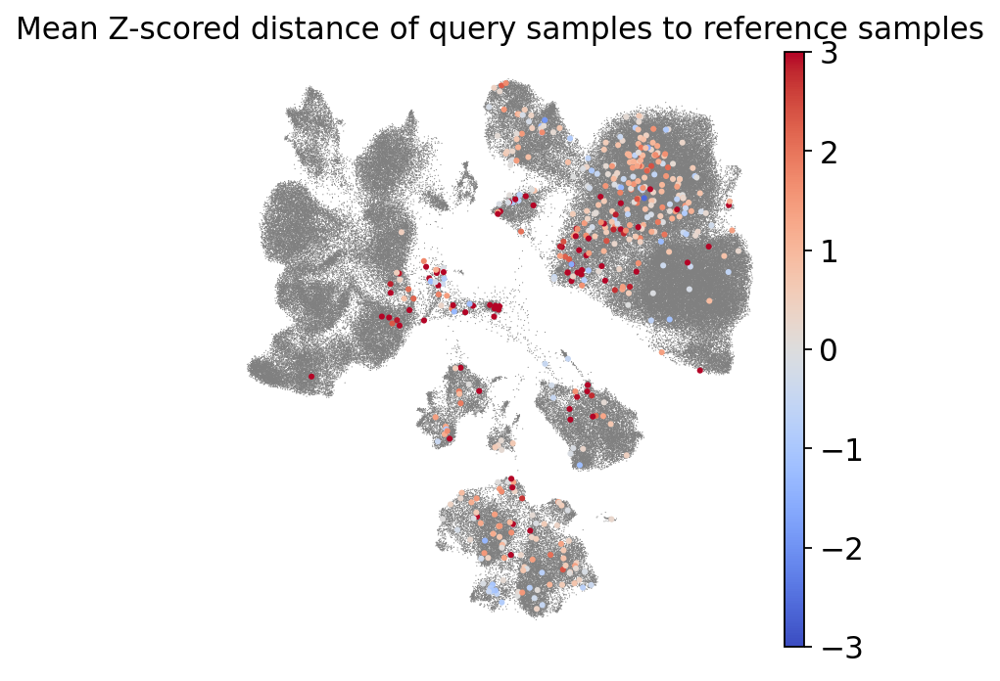

In [64]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease, color_by="mean_zscore")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


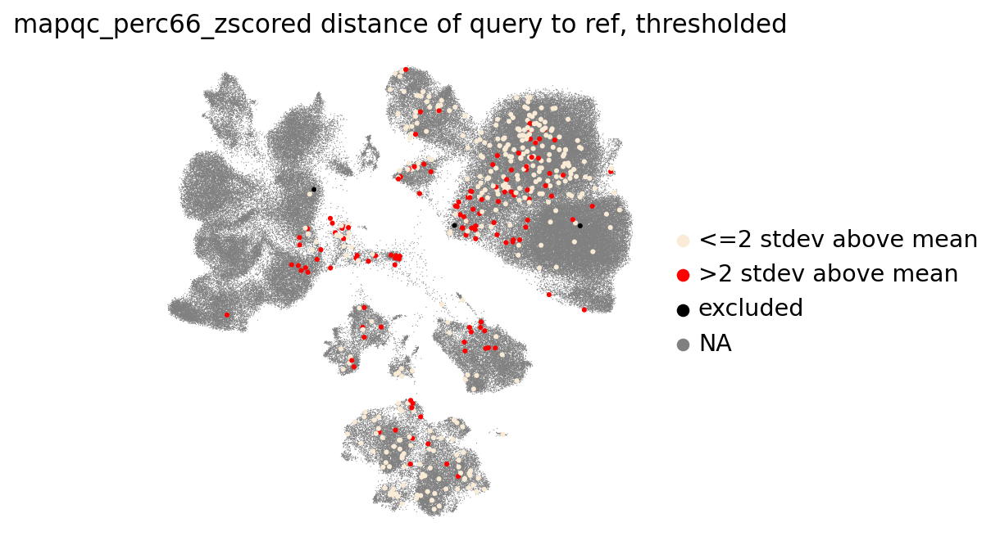

In [65]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease, color_by="percq_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


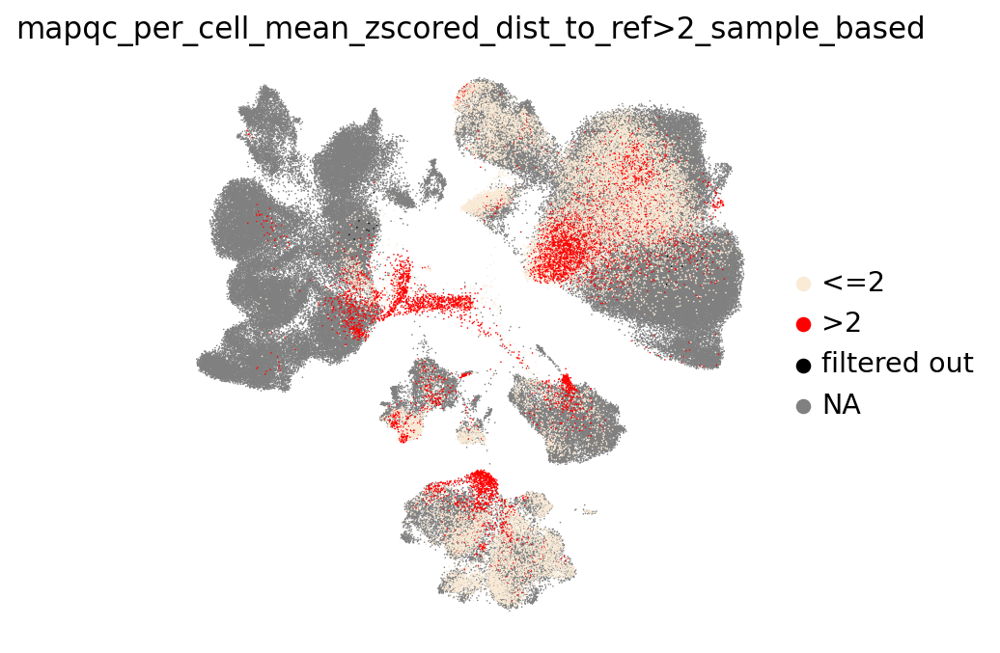

In [66]:
plotting.plot_umap_cell_level_results(results_disease, size=2, sample_based=True)

In [67]:
results_disease.adata.obs["query_sample"] = None
results_disease.adata.obs.loc[
    results_disease.adata.obs.ref_or_query == "query", "query_sample"
] = results_disease.adata.obs.loc[
    results_disease.adata.obs.ref_or_query == "query", "sample"
]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


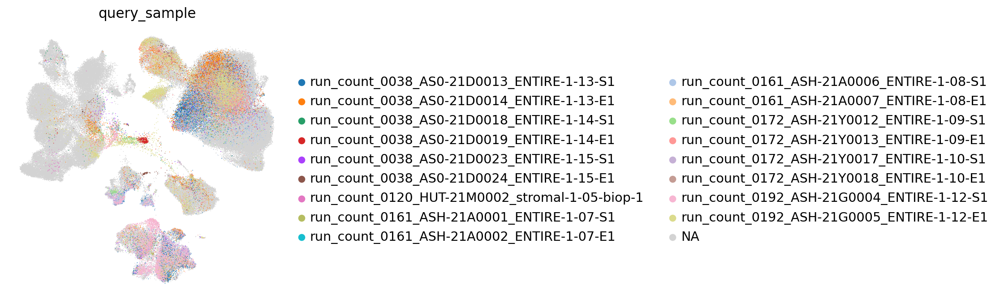

In [68]:
sc.pl.umap(results_disease.adata, color="query_sample", frameon=False, size=2)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


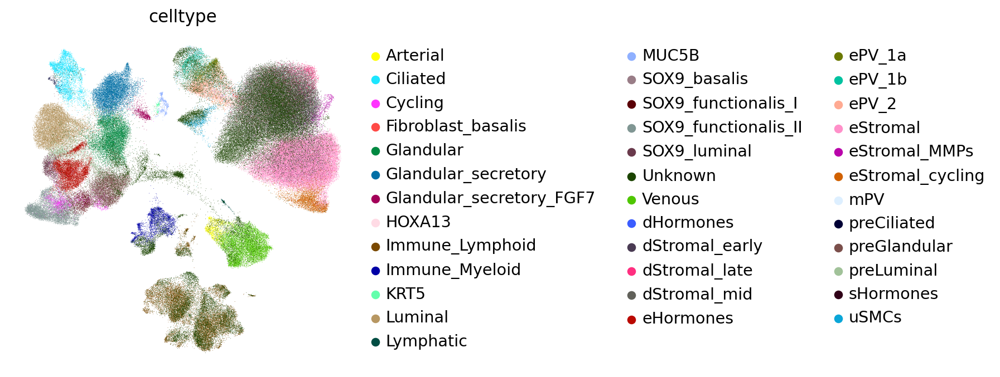

In [69]:
sc.pl.umap(
    results_disease.adata,
    color="celltype",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


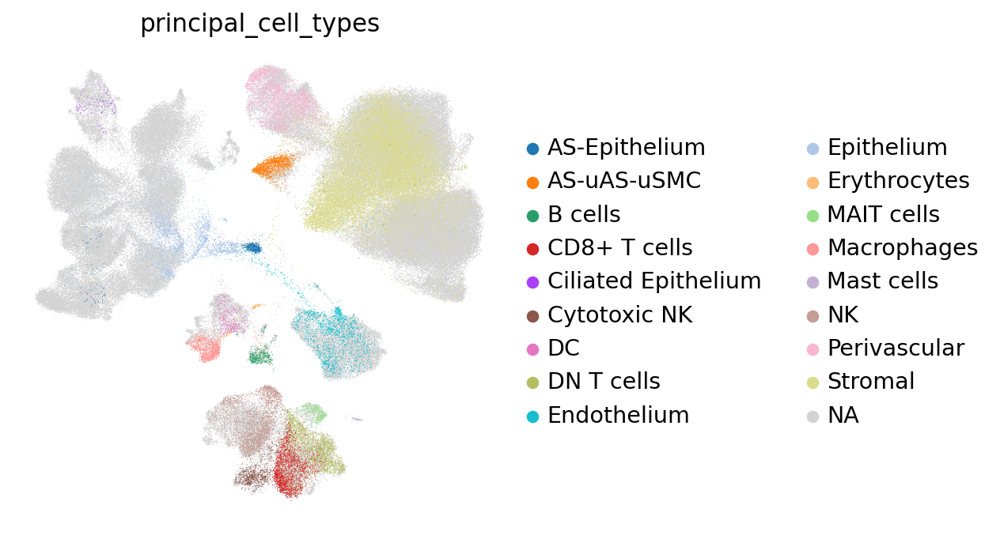

In [70]:
sc.pl.umap(
    results_disease.adata,
    color="principal_cell_types",
    # groups=""
    frameon=False,
    size=1,
)

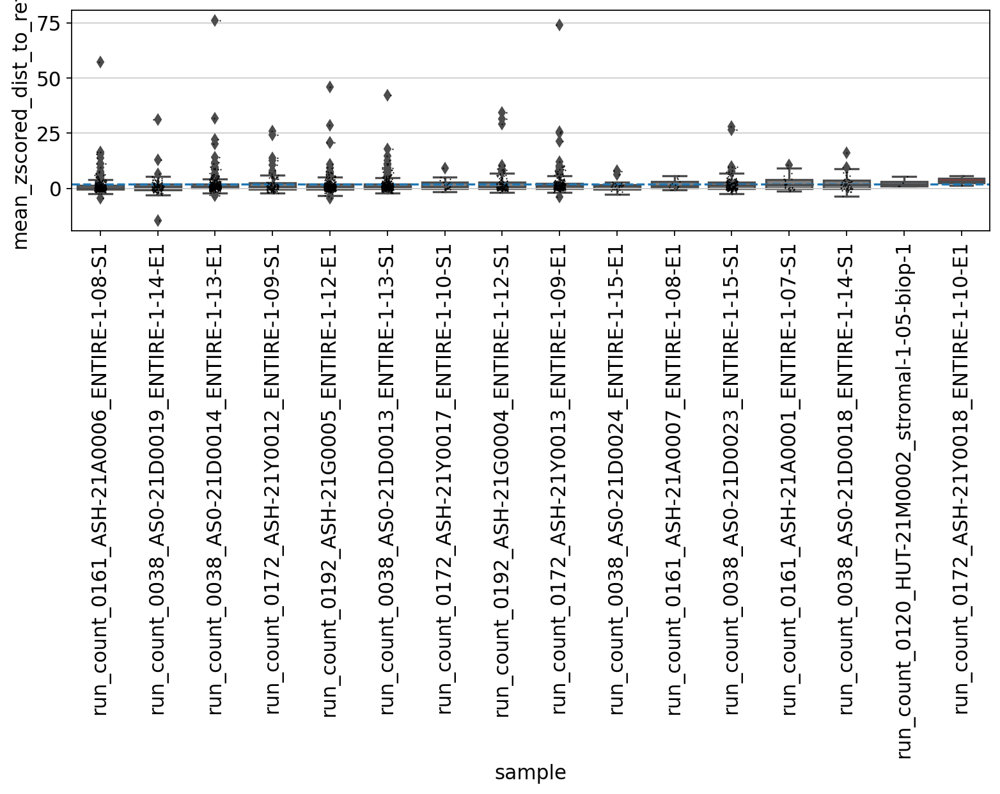

In [71]:
plotting.plot_sample_distances_to_reference(results_disease)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


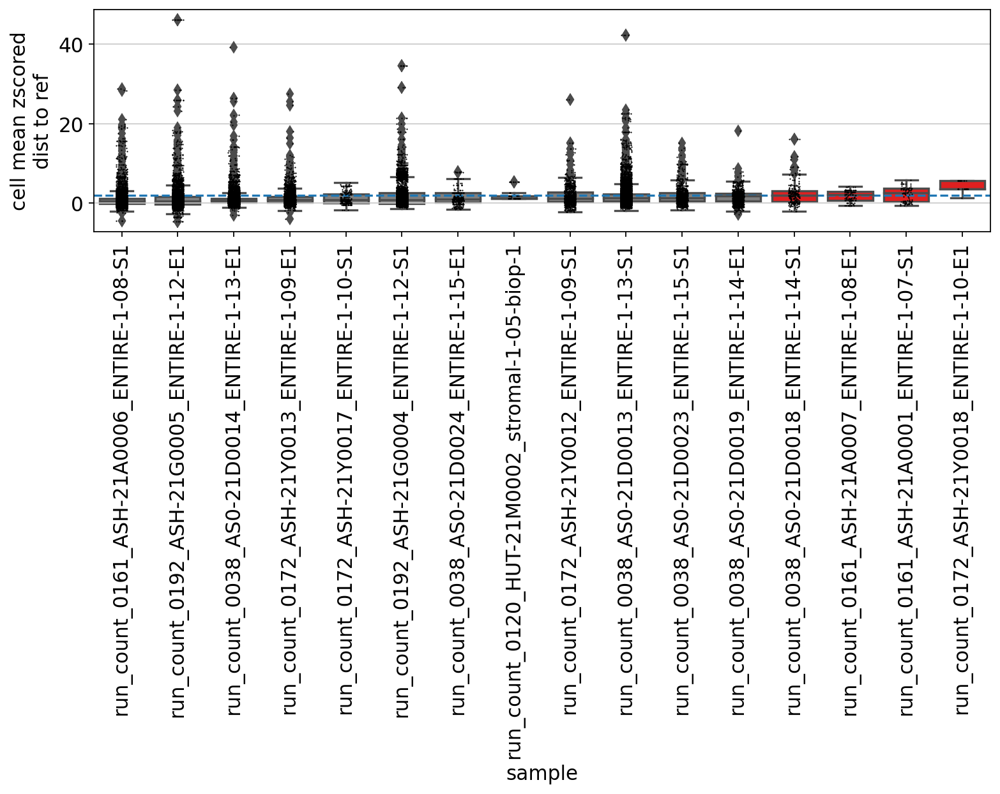

In [72]:
plotting.plot_sample_distances_to_reference_cell_level(results_disease)

### Store results:

In [73]:
results_healthy.save("./HECA_results_healthy.pkl")
results_disease.save("./HECA_results_disease.pkl")

saving results at ./HECA_results_healthy.pkl
saving results at ./HECA_results_disease.pkl


#### some downstream analysis:

In [74]:
raise error here

SyntaxError: invalid syntax (3732856703.py, line 1)

ERROR:root:Cannot parse: 1:12: raise error here
Traceback (most recent call last):
  File "/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/lab_black.py", line 218, in format_cell
    formatted_code = _format_code(cell)
  File "/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/lab_black.py", line 29, in _format_code
    return format_str(src_contents=code, mode=FileMode())
  File "src/black/__init__.py", line 1079, in format_str
  File "src/black/__init__.py", line 1089, in _format_str_once
  File "src/black/parsing.py", line 100, in lib2to3_parse
black.parsing.InvalidInput: Cannot parse: 1:12: raise error here


In [ ]:
sc.tl.leiden(adata, resolution=2)

In [ ]:
sc.pl.umap(adata, color="leiden", groups="12", palette="rainbow")

In [ ]:
sc.pl.umap(adata, color="leiden", groups="47", palette="rainbow")

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
cell_type_key = "principal_cell_types"

In [ ]:
test_df = results_healthy.cell_results.copy()
test_df[cell_type_key] = adata.obs.loc[test_df.index, cell_type_key]
test_df[sample_key] = adata.obs.loc[test_df.index, sample_key]
test_df["leiden_2"] = adata.obs.loc[test_df.index, "leiden"]
sample_ct_zscore = (
    test_df.groupby([sample_key, cell_type_key])
    .agg({"mapqc_mean_zscored_q_dist_to_ref_across_cells_nhoods": "mean"})
    .unstack()
)
sample_ct_zscore.dropna(axis=0, how="all", inplace=True)

In [ ]:
test_df_disease = test_df.copy()

In [ ]:
test_df_healthy = test_df.copy()

In [ ]:
sample_ct_zscore_healthy = sample_ct_zscore.copy()

In [ ]:
sample_ct_zscore_disease = sample_ct_zscore.copy()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.heatmap(sample_ct_zscore_healthy, vmin=0, vmax=3, cmap="Reds", ax=ax)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(sample_ct_zscore_disease, vmin=0, vmax=3, cmap="Reds", ax=ax)

In [ ]:
sns.heatmap(sample_ct_zscore_healthy, vmin=0, vmax=3, cmap="Reds")

In [ ]:
fig, ax = plt.subplots()
sns.boxplot(
    test_df_healthy,
    x="principal_cell_types",
    y="mapqc_mean_zscored_q_dist_to_ref_across_cells_nhoods",
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)
ax.hlines(y=2, linestyles="--", xmin=0, xmax=20)

In [ ]:
fig, ax = plt.subplots()
sns.boxplot(
    test_df_disease,
    x="principal_cell_types",
    y="mapqc_mean_zscored_q_dist_to_ref_across_cells_nhoods",
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)
ax.hlines(y=2, linestyles="--", xmin=0, xmax=20)

In [ ]:
fig, ax = plt.subplots(figsize=(20, 4))
sns.boxplot(
    test_df_healthy,
    x="leiden_2",
    y="mapqc_mean_zscored_q_dist_to_ref_across_cells_nhoods",
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)
ax.hlines(y=2, linestyles="--", xmin=0, xmax=20)

In [ ]:
fig, ax = plt.subplots(figsize=(40, 4))
sns.boxplot(
    test_df_disease,
    x="leiden_2",
    y="mapqc_mean_zscored_q_dist_to_ref_across_cells_nhoods",
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)
ax.hlines(y=2, linestyles="--", xmin=0, xmax=20)